In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
stops = pd.read_csv("stops.txt")
routes = pd.read_csv("routes.txt")
trips = pd.read_csv("trips.txt")
stop_times = pd.read_csv("stop_times.txt")

In [3]:
print("STOPS:", stops.shape)
display(stops.head())

print("ROUTES:", routes.shape)
display(routes.head())

print("TRIPS:", trips.shape)
display(trips.head())

print("STOP TIMES:", stop_times.shape)
display(stop_times.head())

STOPS: (389, 7)


,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,location_type
0,39670da2-d430-494f-a8d4-89090ac39481,1045,Transit Ctr,NaN,36.316802,-82.355094,0
1,ed80d745-b5f4-41e0-9608-e4d49b5f35c6,1001,N. Boone & W. Fairview,NaN,36.319096,-82.356448,0
2,16233924-a1d9-42e1-b7e8-6f0917e9ea75,7036,W. Fairview - Library,NaN,36.320084,-82.354941,0
3,61ad3cdd-83e9-47e5-8efc-97e60676a383,7037,N. Roan & E. Watauga,NaN,36.321340,-82.356191,0
4,4c69fb7c-9a36-4b97-8eb3-2799b99813d1,8003,E. Watauga & Welbourne,NaN,36.322768,-82.354935,0


ROUTES: (12, 8)


,route_id,agency_id,route_short_name,route_long_name,route_desc,route_type,route_color,route_text_color
0,7a16600c-94c6-448d-8cca-10cca945fb25,03beec22-8e91-46ec-ae00-ab896118944b,BUCE,Bucshot Evening,Main,3,7B68EE,000000
1,ff9b4283-3534-4394-a114-8fab9ec3ecc0,03beec22-8e91-46ec-ae00-ab896118944b,GR,Green,Main,3,008000,000000
2,b0469d9e-b378-42b5-bb3f-5ea07b2b9411,03beec22-8e91-46ec-ae00-ab896118944b,GO,Gold,Main,3,FFD700,000000
3,4ac5a41c-cfb5-49e7-bd5e-0f360169ea70,03beec22-8e91-46ec-ae00-ab896118944b,BUCG,Bucshot Gold,Main,3,FFFF00,000000
4,33e3cd45-18d3-49e2-93b4-004a054df21d,03beec22-8e91-46ec-ae00-ab896118944b,BUCSV,Bucshot Safe Voyage,Main,3,9370DB,000000


TRIPS: (333, 7)


,route_id,service_id,trip_id,shape_id,trip_headsign,direction_id,block_id
0,ff9b4283-3534-4394-a114-8fab9ec3ecc0,ceb17569-62f3-4fec-b659-1b6c9941aee0,ec9285ba-34bb-4839-9663-1f8bfb8fccac,48efaceb-0032-434f-a0f6-53cd385d6740,NaN,0,0e494f34-c444-4517-91dd-aca3911c59cf
1,b0469d9e-b378-42b5-bb3f-5ea07b2b9411,4dd6ca9b-0a39-4e9e-8286-93c64cb9b2c0,e11fecbb-bcb2-4d5a-a544-1aa70670ae26,78142c8d-5539-4f67-8a26-4a091b071b9b,NaN,0,0ff0cc7a-39eb-424b-800d-ca2fda498378
2,b0469d9e-b378-42b5-bb3f-5ea07b2b9411,4dd6ca9b-0a39-4e9e-8286-93c64cb9b2c0,a56d2c91-cd8c-4d2d-86c6-bd1deddb271a,78142c8d-5539-4f67-8a26-4a091b071b9b,NaN,0,0ff0cc7a-39eb-424b-800d-ca2fda498378
3,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,ceb17569-62f3-4fec-b659-1b6c9941aee0,52d600af-b974-4972-b8b4-e6c80a748917,0a7b0520-7a53-46ab-baec-b56c75b698f9,NaN,0,0d73adfc-dfcc-4e43-a84f-02e1bbfcf7d7
4,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,ceb17569-62f3-4fec-b659-1b6c9941aee0,6d2ba13b-5afb-4645-8863-86a1c623e257,484251aa-ecf9-4c3f-9b78-29b741a039e0,NaN,1,0d73adfc-dfcc-4e43-a84f-02e1bbfcf7d7


STOP TIMES: (9360, 9)


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,pickup_type,drop_off_type,shape_dist_traveled,timepoint
0,ec9285ba-34bb-4839-9663-1f8bfb8fccac,13:15:00,13:15:00,39670da2-d430-494f-a8d4-89090ac39481,0,0,0,0.00,1
1,ec9285ba-34bb-4839-9663-1f8bfb8fccac,13:16:00,13:16:00,ed80d745-b5f4-41e0-9608-e4d49b5f35c6,4,0,0,283.99,1
2,ec9285ba-34bb-4839-9663-1f8bfb8fccac,13:16:28,13:16:28,16233924-a1d9-42e1-b7e8-6f0917e9ea75,7,0,0,470.64,0
3,ec9285ba-34bb-4839-9663-1f8bfb8fccac,13:17:00,13:17:00,61ad3cdd-83e9-47e5-8efc-97e60676a383,10,0,0,683.46,1
4,ec9285ba-34bb-4839-9663-1f8bfb8fccac,13:17:18,13:17:18,4c69fb7c-9a36-4b97-8eb3-2799b99813d1,13,0,0,902.16,0


Step 2A — Check missing values

In [4]:
print("STOPS missing values:")
print(stops.isnull().sum())

print("\nROUTES missing values:")
print(routes.isnull().sum())

print("\nTRIPS missing values:")
print(trips.isnull().sum())

print("\nSTOP TIMES missing values:")
print(stop_times.isnull().sum())

STOPS missing values:
stop_id            0
stop_code          0
stop_name          0
stop_desc        389
stop_lat           0
stop_lon           0
location_type      0
dtype: int64

ROUTES missing values:
route_id            0
agency_id           0
route_short_name    0
route_long_name     0
route_desc          0
route_type          0
route_color         0
route_text_color    0
dtype: int64

TRIPS missing values:
route_id           0
service_id         0
trip_id            0
shape_id           0
trip_headsign    333
direction_id       0
block_id           0
dtype: int64

STOP TIMES missing values:
trip_id                0
arrival_time           0
departure_time         0
stop_id                0
stop_sequence          0
pickup_type            0
drop_off_type          0
shape_dist_traveled    0
timepoint              0
dtype: int64


Step 2B — Check duplicates

In [5]:
print("Duplicate rows:")
print("Stops:", stops.duplicated().sum())
print("Routes:", routes.duplicated().sum())
print("Trips:", trips.duplicated().sum())
print("Stop Times:", stop_times.duplicated().sum())

Duplicate rows:
Stops: 0
Routes: 0
Trips: 0
Stop Times: 0


Step 2C — Create clean versions with only the columns we need

In [6]:
# Keep only the columns needed for the project

stops_clean = stops[
    ["stop_id", "stop_code", "stop_name", "stop_lat", "stop_lon"]
].copy()

routes_clean = routes[
    ["route_id", "route_short_name", "route_long_name"]
].copy()

trips_clean = trips[
    ["route_id", "trip_id", "direction_id"]
].copy()

stop_times_clean = stop_times[
    ["trip_id", "stop_id", "stop_sequence"]
].copy()

# Sort stops within each trip in travel order
stop_times_clean = stop_times_clean.sort_values(
    ["trip_id", "stop_sequence"]
).reset_index(drop=True)

print("Cleaned data shapes:")
print("Stops:", stops_clean.shape)
print("Routes:", routes_clean.shape)
print("Trips:", trips_clean.shape)
print("Stop Times:", stop_times_clean.shape)

Cleaned data shapes:
Stops: (389, 5)
Routes: (12, 3)
Trips: (333, 3)
Stop Times: (9360, 3)


Step 3A — Create consecutive stop pairs

In [7]:
# Add route information to each stop-time record
trip_stops = stop_times_clean.merge(
    trips_clean,
    on="trip_id",
    how="left"
)

# Make sure stops are in the correct travel order
trip_stops = trip_stops.sort_values(
    ["trip_id", "stop_sequence"]
).reset_index(drop=True)

# Find the next stop within each trip
trip_stops["next_stop_id"] = (
    trip_stops.groupby("trip_id")["stop_id"].shift(-1)
)

# Keep only rows that have a next stop
edges = trip_stops.dropna(subset=["next_stop_id"])[
    [
        "trip_id",
        "route_id",
        "direction_id",
        "stop_id",
        "next_stop_id"
    ]
].copy()

print("Number of raw graph edges:", len(edges))
display(edges.head(10))

Number of raw graph edges: 9027


,trip_id,route_id,direction_id,stop_id,next_stop_id
0,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,39670da2-d430-494f-a8d4-89090ac39481,da2da3b2-3e1e-4adb-a5ab-015deab4d427
1,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,da2da3b2-3e1e-4adb-a5ab-015deab4d427,2af0e9d2-140a-4e71-8c25-18a80dae6012
2,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,2af0e9d2-140a-4e71-8c25-18a80dae6012,bbb6bd62-d434-45b9-8c7e-b7583c511693
3,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,bbb6bd62-d434-45b9-8c7e-b7583c511693,00283b0d-24b1-41f4-926b-8f6541f1f7e2
4,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,00283b0d-24b1-41f4-926b-8f6541f1f7e2,9421b808-38ca-4106-988c-04ae61ec5103
5,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,9421b808-38ca-4106-988c-04ae61ec5103,1d16db48-22a3-4c80-936b-ab7d644c8a1e
6,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,1d16db48-22a3-4c80-936b-ab7d644c8a1e,02cf56a8-3009-4640-9a09-e38348a17cbc
7,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,02cf56a8-3009-4640-9a09-e38348a17cbc,55370b28-37d6-4660-9095-7d8c480f1a90
8,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,55370b28-37d6-4660-9095-7d8c480f1a90,f2e36b17-2aa5-468d-bfce-9ab796e93f5e
9,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,f2e36b17-2aa5-468d-bfce-9ab796e93f5e,c139663b-e34b-4f5b-959a-05cfb227e6f5


Step 3B — Remove repeated connections and add stop information

In [8]:
# Keep one copy of each directed stop-to-stop connection
graph_edges = edges.drop_duplicates(
    subset=["stop_id", "next_stop_id"]
).copy()

print("Raw edges:", len(edges))
print("Unique directed edges:", len(graph_edges))

Raw edges: 9027
Unique directed edges: 431


In [9]:
# Information for the starting stop
from_stops = stops_clean[
    ["stop_id", "stop_name", "stop_lat", "stop_lon"]
].rename(columns={
    "stop_name": "from_stop_name",
    "stop_lat": "from_lat",
    "stop_lon": "from_lon"
})

# Information for the destination stop
to_stops = stops_clean[
    ["stop_id", "stop_name", "stop_lat", "stop_lon"]
].rename(columns={
    "stop_id": "next_stop_id",
    "stop_name": "to_stop_name",
    "stop_lat": "to_lat",
    "stop_lon": "to_lon"
})

# Attach information to each edge
graph_edges = graph_edges.merge(
    from_stops,
    on="stop_id",
    how="left"
)

graph_edges = graph_edges.merge(
    to_stops,
    on="next_stop_id",
    how="left"
)

display(graph_edges.head(10))

,trip_id,route_id,direction_id,stop_id,next_stop_id,from_stop_name,from_lat,from_lon,to_stop_name,to_lat,to_lon
0,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,39670da2-d430-494f-a8d4-89090ac39481,da2da3b2-3e1e-4adb-a5ab-015deab4d427,Transit Ctr,36.316802,-82.355094,S. Roan & W. Walnut,36.315067,-82.348946
1,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,da2da3b2-3e1e-4adb-a5ab-015deab4d427,2af0e9d2-140a-4e71-8c25-18a80dae6012,S. Roan & W. Walnut,36.315067,-82.348946,S. Roan & W. Pine,36.313469,-82.347520
2,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,2af0e9d2-140a-4e71-8c25-18a80dae6012,bbb6bd62-d434-45b9-8c7e-b7583c511693,S. Roan & W. Pine,36.313469,-82.347520,S. Roan & W. Chestnut,36.311033,-82.345419
3,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,bbb6bd62-d434-45b9-8c7e-b7583c511693,00283b0d-24b1-41f4-926b-8f6541f1f7e2,S. Roan & W. Chestnut,36.311033,-82.345419,S. Roan & Highland,36.308873,-82.343078
4,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,00283b0d-24b1-41f4-926b-8f6541f1f7e2,9421b808-38ca-4106-988c-04ae61ec5103,S. Roan & Highland,36.308873,-82.343078,Highland & Linden,36.309796,-82.341137
5,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,9421b808-38ca-4106-988c-04ae61ec5103,1d16db48-22a3-4c80-936b-ab7d644c8a1e,Highland & Linden,36.309796,-82.341137,Highland - Taylor Ridge,36.311625,-82.338007
6,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,1d16db48-22a3-4c80-936b-ab7d644c8a1e,02cf56a8-3009-4640-9a09-e38348a17cbc,Highland - Taylor Ridge,36.311625,-82.338007,Highland & E. Maple,36.312767,-82.336025
7,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,02cf56a8-3009-4640-9a09-e38348a17cbc,55370b28-37d6-4660-9095-7d8c480f1a90,Highland & E. Maple,36.312767,-82.336025,King Springs & Legion,36.313616,-82.333809
8,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,55370b28-37d6-4660-9095-7d8c480f1a90,f2e36b17-2aa5-468d-bfce-9ab796e93f5e,King Springs & Legion,36.313616,-82.333809,Milligan Hwy - Past Shell,36.308977,-82.329686
9,0090063a-14cf-48fc-957a-a6d83b663c54,e725f630-8c63-4cc4-9dd0-ada8e5f615bf,1,f2e36b17-2aa5-468d-bfce-9ab796e93f5e,c139663b-e34b-4f5b-959a-05cfb227e6f5,Milligan Hwy - Past Shell,36.308977,-82.329686,Swadley - Beaver Hollow Apts,36.305107,-82.325077


Step 3C — Calculate distance between connected stops

In [10]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometers

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c

In [11]:
graph_edges["distance_km"] = graph_edges.apply(
    lambda row: haversine(
        row["from_lat"],
        row["from_lon"],
        row["to_lat"],
        row["to_lon"]
    ),
    axis=1
)

display(
    graph_edges[
        ["from_stop_name", "to_stop_name", "distance_km"]
    ].head(10)
)

,from_stop_name,to_stop_name,distance_km
0,Transit Ctr,S. Roan & W. Walnut,0.583631
1,S. Roan & W. Walnut,S. Roan & W. Pine,0.218862
2,S. Roan & W. Pine,S. Roan & W. Chestnut,0.329863
3,S. Roan & W. Chestnut,S. Roan & Highland,0.318884
4,S. Roan & Highland,Highland & Linden,0.201947
5,Highland & Linden,Highland - Taylor Ridge,0.346436
6,Highland - Taylor Ridge,Highland & E. Maple,0.218319
7,Highland & E. Maple,King Springs & Legion,0.219854
8,King Springs & Legion,Milligan Hwy - Past Shell,0.634444
9,Milligan Hwy - Past Shell,Swadley - Beaver Hollow Apts,0.596503


Step 4A — Build the actual search graph

In [12]:
# Create the graph
graph = {stop_id: [] for stop_id in stops_clean["stop_id"]}

# Add each directed connection to the graph
for _, row in graph_edges.iterrows():
    graph[row["stop_id"]].append(
        (row["next_stop_id"], row["distance_km"])
    )

# Check the graph
print("Number of nodes:", len(graph))
print(
    "Number of directed edges:",
    sum(len(neighbors) for neighbors in graph.values())
)

Number of nodes: 389
Number of directed edges: 431


Step 4B — Make the graph readable

In [13]:
# Create lookup dictionaries

stop_names = dict(
    zip(stops_clean["stop_id"], stops_clean["stop_name"])
)

stop_coords = {
    row["stop_id"]: (row["stop_lat"], row["stop_lon"])
    for _, row in stops_clean.iterrows()
}

print("Stop names stored:", len(stop_names))
print("Stop coordinates stored:", len(stop_coords))

Stop names stored: 389
Stop coordinates stored: 389


In [14]:
# Find the Transit Center ID
transit_id = stops_clean.loc[
    stops_clean["stop_name"] == "Transit Ctr",
    "stop_id"
].iloc[0]

print("Starting stop:", stop_names[transit_id])

print("\nStops directly reachable from Transit Ctr:")

for neighbor, distance in graph[transit_id]:
    print(
        stop_names[neighbor],
        "-",
        round(distance, 3),
        "km"
    )

Starting stop: Transit Ctr

Stops directly reachable from Transit Ctr:
S. Roan & W. Walnut - 0.584 km
N. Boone & W. Fairview - 0.282 km
Walnut St. Parking Lot - 1.429 km
W. Mkt & W. Watauga - 0.408 km
S. Boone & Lamont - 0.329 km
S. Roan & E. Maple - 0.689 km
N. Boone & W. Watauga - 0.425 km
Wilson & W. Watauga - Wat. Sq. Apts - 0.445 km


Step 5 — BFS
We will now implement the first algorithm from  proposal: Breadth-First Search (BFS). BFS ignores distance while searching and explores stops level by level

Step 5A — Create the BFS function

In [15]:
from collections import deque

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    visited = {start}
    nodes_expanded = 0

    while queue:
        current, path = queue.popleft()
        nodes_expanded += 1

        # Goal found
        if current == goal:
            return path, nodes_expanded

        # Explore neighboring stops
        for neighbor, distance in graph[current]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return None, nodes_expanded

In [16]:
start_node = transit_id
goal_node = list(stop_names.keys())[5] # Example goal: the 6th stop in the list

path, nodes_expanded = bfs(graph, start_node, goal_node)

print(f"Path from {stop_names[start_node]} to {stop_names[goal_node]}:")
if path:
    for stop_id in path:
        print(f"- {stop_names[stop_id]}")
else:
    print("No path found.")

print(f"\nNodes expanded: {nodes_expanded}")

Path from Transit Ctr to E. Watauga & Elm - Blankenship Pharm:
- Transit Ctr
- N. Boone & W. Watauga
- E. Watauga & Welbourne
- E. Watauga & Elm - Blankenship Pharm

Nodes expanded: 27


Step 5B — Test BFS
Let's search from:
Transit Ctr → King Springs & Legion

In [17]:
goal_id = stops_clean.loc[
    stops_clean["stop_name"] == "King Springs & Legion",
    "stop_id"
].iloc[0]

bfs_path, bfs_expanded = bfs(
    graph,
    transit_id,
    goal_id
)

print("BFS Path:")

for stop in bfs_path:
    print(stop_names[stop])

print("\nNumber of stops in path:", len(bfs_path))
print("Nodes expanded:", bfs_expanded)

BFS Path:
Transit Ctr
S. Roan & W. Walnut
S. Roan & W. Pine
S. Roan & W. Chestnut
S. Roan & Highland
Highland & Linden
Highland - Taylor Ridge
Highland & E. Maple
King Springs & Legion

Number of stops in path: 9
Nodes expanded: 92


Step 5C — Calculate BFS path distance

In [18]:
def calculate_path_distance(path, graph):
    total_distance = 0

    for i in range(len(path) - 1):
        current = path[i]
        next_stop = path[i + 1]

        for neighbor, distance in graph[current]:
            if neighbor == next_stop:
                total_distance += distance
                break

    return total_distance

In [19]:
bfs_distance = calculate_path_distance(bfs_path, graph)

print("BFS Results")
print("Number of stops:", len(bfs_path))
print("Number of edges:", len(bfs_path) - 1)
print("Path distance:", round(bfs_distance, 3), "km")
print("Nodes expanded:", bfs_expanded)

BFS Results
Number of stops: 9
Number of edges: 8
Path distance: 2.438 km
Nodes expanded: 92


Step 5D — Measure BFS execution time

In [20]:
import time
import statistics

bfs_times = []

for _ in range(100):
    start_time = time.perf_counter()

    bfs_path, bfs_expanded = bfs(
        graph,
        transit_id,
        goal_id
    )

    end_time = time.perf_counter()

    bfs_times.append((end_time - start_time) * 1000)

bfs_time_ms = statistics.median(bfs_times)

print("BFS execution time:", round(bfs_time_ms, 4), "ms")

BFS execution time: 0.043 ms


Step 6: Uniform Cost Search (UCS).

**Step 6A — Create the UCS function**

In [21]:
import heapq

def ucs(graph, start, goal):
    priority_queue = [(0, start, [start])]
    best_cost = {start: 0}
    nodes_expanded = 0

    while priority_queue:
        cost, current, path = heapq.heappop(priority_queue)

        # Ignore an outdated, more expensive entry
        if cost > best_cost[current]:
            continue

        nodes_expanded += 1

        # Goal found
        if current == goal:
            return path, cost, nodes_expanded

        # Explore neighboring stops
        for neighbor, distance in graph[current]:
            new_cost = cost + distance

            if neighbor not in best_cost or new_cost < best_cost[neighbor]:
                best_cost[neighbor] = new_cost

                heapq.heappush(
                    priority_queue,
                    (new_cost, neighbor, path + [neighbor])
                )

    return None, float("inf"), nodes_expanded

In [22]:
ucs_path, ucs_distance, ucs_expanded = ucs(
    graph,
    transit_id,
    goal_id
)

print("UCS Path:")

for stop in ucs_path:
    print(stop_names[stop])

print("\nNumber of stops:", len(ucs_path))
print("Number of edges:", len(ucs_path) - 1)
print("Path distance:", round(ucs_distance, 3), "km")
print("Nodes expanded:", ucs_expanded)

UCS Path:
Transit Ctr
S. Roan & W. Walnut
S. Roan & W. Pine
S. Roan & W. Chestnut
S. Roan & Highland
Highland & Linden
Highland - Taylor Ridge
Highland & E. Maple
King Springs & Legion

Number of stops: 9
Number of edges: 8
Path distance: 2.438 km
Nodes expanded: 81


Step 6B — Measure UCS execution time

In [23]:
ucs_times = []

for _ in range(100):
    start_time = time.perf_counter()

    ucs_path, ucs_distance, ucs_expanded = ucs(
        graph,
        transit_id,
        goal_id
    )

    end_time = time.perf_counter()

    ucs_times.append((end_time - start_time) * 1000)

ucs_time_ms = statistics.median(ucs_times)

print("UCS execution time:", round(ucs_time_ms, 4), "ms")

UCS execution time: 0.0768 ms


Step 7: Greedy Best-First Search.

Step 7A — Create Greedy Search

In [24]:
def heuristic(stop_id, goal_id):
    lat1, lon1 = stop_coords[stop_id]
    lat2, lon2 = stop_coords[goal_id]

    return haversine(lat1, lon1, lat2, lon2)


def greedy_search(graph, start, goal):
    priority_queue = [(heuristic(start, goal), start, [start])]
    visited = set()
    nodes_expanded = 0

    while priority_queue:
        h, current, path = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)
        nodes_expanded += 1

        if current == goal:
            return path, nodes_expanded

        for neighbor, distance in graph[current]:
            if neighbor not in visited:
                heapq.heappush(
                    priority_queue,
                    (
                        heuristic(neighbor, goal),
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None, nodes_expanded

Step 7B — Test Greedy

In [25]:
greedy_path, greedy_expanded = greedy_search(
    graph,
    transit_id,
    goal_id
)

greedy_distance = calculate_path_distance(
    greedy_path,
    graph
)

print("Greedy Path:")

for stop in greedy_path:
    print(stop_names[stop])

print("\nNumber of stops:", len(greedy_path))
print("Number of edges:", len(greedy_path) - 1)
print("Path distance:", round(greedy_distance, 3), "km")
print("Nodes expanded:", greedy_expanded)

Greedy Path:
Transit Ctr
S. Roan & W. Walnut
S. Roan & W. Pine
S. Roan & W. Chestnut
S. Roan & Highland
Highland & Linden
Highland - Taylor Ridge
Highland & E. Maple
King Springs & Legion

Number of stops: 9
Number of edges: 8
Path distance: 2.438 km
Nodes expanded: 14


Step 7C — Measure Greedy execution time

In [26]:
greedy_times = []

for _ in range(100):
    start_time = time.perf_counter()

    greedy_path, greedy_expanded = greedy_search(
        graph,
        transit_id,
        goal_id
    )

    end_time = time.perf_counter()

    greedy_times.append((end_time - start_time) * 1000)

greedy_time_ms = statistics.median(greedy_times)

print("Greedy execution time:", round(greedy_time_ms, 4), "ms")

Greedy execution time: 0.0331 ms


Step 8A — Create the A* function

In [27]:
def astar(graph, start, goal):
    priority_queue = [
        (heuristic(start, goal), 0, start, [start])
    ]

    best_cost = {start: 0}
    nodes_expanded = 0

    while priority_queue:
        f, g, current, path = heapq.heappop(priority_queue)

        # Ignore outdated entries
        if g > best_cost[current]:
            continue

        nodes_expanded += 1

        # Goal found
        if current == goal:
            return path, g, nodes_expanded

        # Explore neighboring stops
        for neighbor, distance in graph[current]:

            new_g = g + distance

            if neighbor not in best_cost or new_g < best_cost[neighbor]:

                best_cost[neighbor] = new_g

                h = heuristic(neighbor, goal)
                new_f = new_g + h

                heapq.heappush(
                    priority_queue,
                    (
                        new_f,
                        new_g,
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None, float("inf"), nodes_expanded

Step 8B — Test A*

In [28]:
astar_path, astar_distance, astar_expanded = astar(
    graph,
    transit_id,
    goal_id
)

print("A* Path:")

for stop in astar_path:
    print(stop_names[stop])

print("\nNumber of stops:", len(astar_path))
print("Number of edges:", len(astar_path) - 1)
print("Path distance:", round(astar_distance, 3), "km")
print("Nodes expanded:", astar_expanded)

A* Path:
Transit Ctr
S. Roan & W. Walnut
S. Roan & W. Pine
S. Roan & W. Chestnut
S. Roan & Highland
Highland & Linden
Highland - Taylor Ridge
Highland & E. Maple
King Springs & Legion

Number of stops: 9
Number of edges: 8
Path distance: 2.438 km
Nodes expanded: 16


Step 8C — Measure A* execution time

In [29]:
astar_times = []

for _ in range(100):
    start_time = time.perf_counter()

    astar_path, astar_distance, astar_expanded = astar(
        graph,
        transit_id,
        goal_id
    )

    end_time = time.perf_counter()

    astar_times.append((end_time - start_time) * 1000)

astar_time_ms = statistics.median(astar_times)

print("A* execution time:", round(astar_time_ms, 4), "ms")

A* execution time: 0.0397 ms


Step 9A — Save this first experiment in a table

In [30]:
results_first_pair = pd.DataFrame({
    "Algorithm": ["BFS", "UCS", "Greedy", "A*"],
    "Stops": [
        len(bfs_path),
        len(ucs_path),
        len(greedy_path),
        len(astar_path)
    ],
    "Edges": [
        len(bfs_path) - 1,
        len(ucs_path) - 1,
        len(greedy_path) - 1,
        len(astar_path) - 1
    ],
    "Distance_km": [
        bfs_distance,
        ucs_distance,
        greedy_distance,
        astar_distance
    ],
    "Nodes_Expanded": [
        bfs_expanded,
        ucs_expanded,
        greedy_expanded,
        astar_expanded
    ],
    "Time_ms": [
        bfs_time_ms,
        ucs_time_ms,
        greedy_time_ms,
        astar_time_ms
    ]
})

display(results_first_pair.round(4))

,Algorithm,Stops,Edges,Distance_km,Nodes_Expanded,Time_ms
0,BFS,9,8,2.4378,92,0.0430
1,UCS,9,8,2.4378,81,0.0768
2,Greedy,9,8,2.4378,14,0.0331
3,A*,9,8,2.4378,16,0.0397


In [31]:
results_first_pair.to_csv(
    "first_pair_results.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


Step 9B: selecting the 25 origin–destination pairs.
1. Find all reachable stop pairs

In [32]:
reachable_pairs = []

for start in graph:
    for goal in graph:
        if start == goal:
            continue

        path, _ = bfs(graph, start, goal)

        if path is not None:
            lat1, lon1 = stop_coords[start]
            lat2, lon2 = stop_coords[goal]

            straight_distance = haversine(
                lat1, lon1,
                lat2, lon2
            )

            reachable_pairs.append({
                "start_id": start,
                "goal_id": goal,
                "start_name": stop_names[start],
                "goal_name": stop_names[goal],
                "straight_distance_km": straight_distance
            })

reachable_df = pd.DataFrame(reachable_pairs)

print("Number of reachable pairs:", len(reachable_df))
display(reachable_df.head())

Number of reachable pairs: 149383


,start_id,goal_id,start_name,goal_name,straight_distance_km
0,39670da2-d430-494f-a8d4-89090ac39481,ed80d745-b5f4-41e0-9608-e4d49b5f35c6,Transit Ctr,N. Boone & W. Fairview,0.282407
1,39670da2-d430-494f-a8d4-89090ac39481,16233924-a1d9-42e1-b7e8-6f0917e9ea75,Transit Ctr,W. Fairview - Library,0.365163
2,39670da2-d430-494f-a8d4-89090ac39481,61ad3cdd-83e9-47e5-8efc-97e60676a383,Transit Ctr,N. Roan & E. Watauga,0.514044
3,39670da2-d430-494f-a8d4-89090ac39481,4c69fb7c-9a36-4b97-8eb3-2799b99813d1,Transit Ctr,E. Watauga & Welbourne,0.663455
4,39670da2-d430-494f-a8d4-89090ac39481,268ab980-b5a5-4c5f-896e-2ddc28abe911,Transit Ctr,E. Watauga & Elm - Blankenship Pharm,0.850061


2. Divide the pairs by distance

In [33]:
reachable_df["distance_group"] = pd.qcut(
    reachable_df["straight_distance_km"],
    5,
    labels=[
        "Very Short",
        "Short",
        "Medium",
        "Long",
        "Very Long"
    ]
)

print(reachable_df["distance_group"].value_counts().sort_index())

distance_group
Very Short    29878
Short         29876
Medium        29877
Long          29876
Very Long     29876
Name: count, dtype: int64


Step 9C — Select the 25 pairs

In [34]:
distance_groups = [
    "Very Short",
    "Short",
    "Medium",
    "Long",
    "Very Long"
]

selected_list = []

for group in distance_groups:
    group_data = reachable_df[
        reachable_df["distance_group"] == group
    ]

    sample = group_data.sample(
        n=5,
        random_state=42
    )

    selected_list.append(sample)

selected_pairs = pd.concat(
    selected_list,
    ignore_index=True
)

# Give each pair an ID
selected_pairs.insert(
    0,
    "pair_id",
    range(1, 26)
)

display(
    selected_pairs[
        [
            "pair_id",
            "distance_group",
            "start_name",
            "goal_name",
            "straight_distance_km"
        ]
    ].round(3)
)

,pair_id,distance_group,start_name,goal_name,straight_distance_km
0,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,1.535
1,2,Very Short,Bldg 178 - Stanton-Gerber Hall,Lamont & Winter,1.704
2,3,Very Short,The Mall - Upper Level,John Exum & Greenway,1.744
3,4,Very Short,W. Watauga - Univ Edge Apts,S. Boone & Lamont,0.392
4,5,Very Short,E. Maple & Grover,N. Boone & W. Unaka,1.420
5,6,Short,E. Watauga & Welbourne,Broyles & Princeton,2.919
6,7,Short,W. Watauga - Univ Edge Apts,Briarcliff,2.594
7,8,Short,Timberlake & Bristol Hwy,E. Oakland - Morris Baker,2.496
8,9,Short,S. Roan & E. Maple,Bldg 53 - Post Office,2.679
9,10,Short,Bristol Hwy - Big Valley Park,E. Oakland - Morris Baker,2.556


In [35]:
print("Total selected pairs:", len(selected_pairs))

print("\nPairs in each group:")
print(
    selected_pairs["distance_group"]
    .value_counts()
    .sort_index()
)

Total selected pairs: 25

Pairs in each group:
distance_group
Very Short    5
Short         5
Medium        5
Long          5
Very Long     5
Name: count, dtype: int64


Step 10A — Create the experiment functio

In [36]:
def test_pair(pair_id, start_id, goal_id, distance_group):
    results = []

    # ---------------- BFS ----------------
    times = []

    for _ in range(100):
        start_time = time.perf_counter()
        bfs_path, bfs_expanded = bfs(graph, start_id, goal_id)
        end_time = time.perf_counter()

        times.append((end_time - start_time) * 1000)

    bfs_time = statistics.median(times)
    bfs_distance = calculate_path_distance(bfs_path, graph)

    results.append({
        "Pair_ID": pair_id,
        "Distance_Group": distance_group,
        "Start": stop_names[start_id],
        "Goal": stop_names[goal_id],
        "Algorithm": "BFS",
        "Route_Found": bfs_path is not None,
        "Stops": len(bfs_path),
        "Edges": len(bfs_path) - 1,
        "Distance_km": bfs_distance,
        "Nodes_Expanded": bfs_expanded,
        "Time_ms": bfs_time
    })

    # ---------------- UCS ----------------
    times = []

    for _ in range(100):
        start_time = time.perf_counter()
        ucs_path, ucs_distance, ucs_expanded = ucs(
            graph, start_id, goal_id
        )
        end_time = time.perf_counter()

        times.append((end_time - start_time) * 1000)

    ucs_time = statistics.median(times)

    results.append({
        "Pair_ID": pair_id,
        "Distance_Group": distance_group,
        "Start": stop_names[start_id],
        "Goal": stop_names[goal_id],
        "Algorithm": "UCS",
        "Route_Found": ucs_path is not None,
        "Stops": len(ucs_path),
        "Edges": len(ucs_path) - 1,
        "Distance_km": ucs_distance,
        "Nodes_Expanded": ucs_expanded,
        "Time_ms": ucs_time
    })

    # ---------------- Greedy ----------------
    times = []

    for _ in range(100):
        start_time = time.perf_counter()
        greedy_path, greedy_expanded = greedy_search(
            graph, start_id, goal_id
        )
        end_time = time.perf_counter()

        times.append((end_time - start_time) * 1000)

    greedy_time = statistics.median(times)
    greedy_distance = calculate_path_distance(
        greedy_path,
        graph
    )

    results.append({
        "Pair_ID": pair_id,
        "Distance_Group": distance_group,
        "Start": stop_names[start_id],
        "Goal": stop_names[goal_id],
        "Algorithm": "Greedy",
        "Route_Found": greedy_path is not None,
        "Stops": len(greedy_path),
        "Edges": len(greedy_path) - 1,
        "Distance_km": greedy_distance,
        "Nodes_Expanded": greedy_expanded,
        "Time_ms": greedy_time
    })

    # ---------------- A* ----------------
    times = []

    for _ in range(100):
        start_time = time.perf_counter()
        astar_path, astar_distance, astar_expanded = astar(
            graph, start_id, goal_id
        )
        end_time = time.perf_counter()

        times.append((end_time - start_time) * 1000)

    astar_time = statistics.median(times)

    results.append({
        "Pair_ID": pair_id,
        "Distance_Group": distance_group,
        "Start": stop_names[start_id],
        "Goal": stop_names[goal_id],
        "Algorithm": "A*",
        "Route_Found": astar_path is not None,
        "Stops": len(astar_path),
        "Edges": len(astar_path) - 1,
        "Distance_km": astar_distance,
        "Nodes_Expanded": astar_expanded,
        "Time_ms": astar_time
    })

    return results

Step 10B — Test it on just Pair 1

In [37]:
pair = selected_pairs.iloc[0]

test_results = test_pair(
    pair["pair_id"],
    pair["start_id"],
    pair["goal_id"],
    pair["distance_group"]
)

test_df = pd.DataFrame(test_results)

display(test_df.round(4))

,Pair_ID,Distance_Group,Start,Goal,Algorithm,Route_Found,Stops,Edges,Distance_km,Nodes_Expanded,Time_ms
0,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,BFS,True,29,28,7.0313,226,0.1091
1,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,UCS,True,29,28,7.0313,39,0.0283
2,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,Greedy,True,29,28,7.1243,30,0.0532
3,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,A*,True,29,28,7.0313,30,0.0563


Step 11 — Run all 25 pairs

In [38]:
all_results = []

for _, pair in selected_pairs.iterrows():

    pair_results = test_pair(
        pair["pair_id"],
        pair["start_id"],
        pair["goal_id"],
        pair["distance_group"]
    )

    all_results.extend(pair_results)

    print("Finished Pair", int(pair["pair_id"]))

# Convert everything into one DataFrame
results_df = pd.DataFrame(all_results)

print("\nTotal result rows:", len(results_df))

display(results_df.round(4))

Finished Pair 1
Finished Pair 2
Finished Pair 3
Finished Pair 4
Finished Pair 5
Finished Pair 6
Finished Pair 7
Finished Pair 8
Finished Pair 9
Finished Pair 10
Finished Pair 11
Finished Pair 12
Finished Pair 13
Finished Pair 14
Finished Pair 15
Finished Pair 16
Finished Pair 17
Finished Pair 18
Finished Pair 19
Finished Pair 20
Finished Pair 21
Finished Pair 22
Finished Pair 23
Finished Pair 24
Finished Pair 25

Total result rows: 100


,Pair_ID,Distance_Group,Start,Goal,Algorithm,Route_Found,Stops,Edges,Distance_km,Nodes_Expanded,Time_ms
0,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,BFS,True,29,28,7.0313,226,0.1341
1,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,UCS,True,29,28,7.0313,39,0.0273
2,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,Greedy,True,29,28,7.1243,30,0.0554
3,1,Very Short,E. Watauga & Welbourne,E. Unaka - Btwn 2 Churches,A*,True,29,28,7.0313,30,0.0567
4,2,Very Short,Bldg 178 - Stanton-Gerber Hall,Lamont & Winter,BFS,True,13,12,3.4369,39,0.0195
...,...,...,...,...,...,...,...,...,...,...,...
95,24,Very Long,Buc Ridge Shelter,Princeton - Evergreen Nursery,A*,True,48,47,15.8383,97,0.2037
96,25,Very Long,N. Roan - John Deere Lands,Broadway & St. Louis,BFS,True,26,25,20.0735,240,0.1161
97,25,Very Long,N. Roan - John Deere Lands,Broadway & St. Louis,UCS,True,26,25,20.0735,260,0.2368
98,25,Very Long,N. Roan - John Deere Lands,Broadway & St. Louis,Greedy,True,26,25,20.0735,26,0.0533


Step 12 — Save the 100 results

In [39]:
import os

# Create a results folder
os.makedirs("results", exist_ok=True)

# Save the complete experiment
results_df.to_csv(
    "results/all_25_pairs_results.csv",
    index=False
)

# Save the 25 selected origin-destination pairs
selected_pairs.to_csv(
    "results/selected_25_pairs.csv",
    index=False
)

print("Files saved successfully.")
print("1. results/all_25_pairs_results.csv")
print("2. results/selected_25_pairs.csv")

Files saved successfully.
1. results/all_25_pairs_results.csv
2. results/selected_25_pairs.csv


Step 13A — Create the summary table

In [40]:
summary = results_df.groupby("Algorithm").agg(
    Route_Found_Rate=("Route_Found", "mean"),
    Average_Stops=("Stops", "mean"),
    Average_Distance_km=("Distance_km", "mean"),
    Average_Nodes_Expanded=("Nodes_Expanded", "mean"),
    Average_Time_ms=("Time_ms", "mean")
).reset_index()

summary["Route_Found_Rate"] = (
    summary["Route_Found_Rate"] * 100
)

display(summary.round(4))

,Algorithm,Route_Found_Rate,Average_Stops,Average_Distance_km,Average_Nodes_Expanded,Average_Time_ms
0,A*,100.0,33.64,11.6590,84.80,0.1805
1,BFS,100.0,32.68,12.1280,185.00,0.1021
2,Greedy,100.0,33.84,12.4947,74.68,0.1660
3,UCS,100.0,33.64,11.6590,159.16,0.1503


Step 14 — First graph: Average Nodes Expanded
This is a very important graph for comparing search effort.

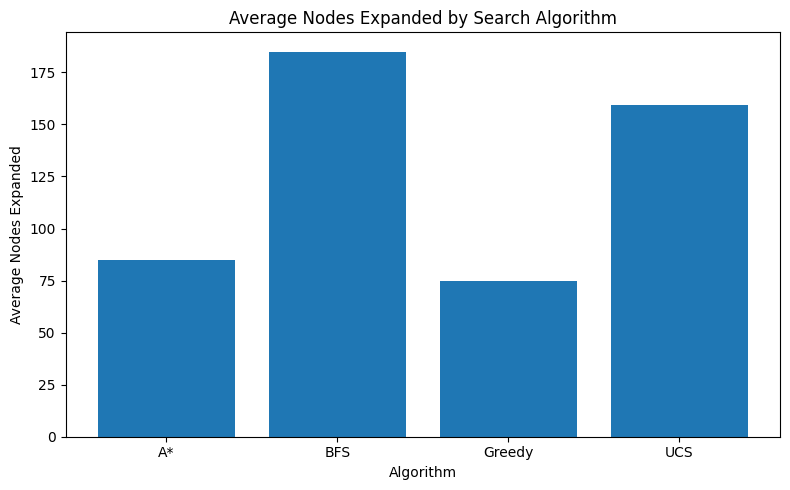

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Nodes_Expanded"]
)

plt.title("Average Nodes Expanded by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Nodes Expanded")

plt.tight_layout()
plt.show()

Step 15 — Average Execution Time graph

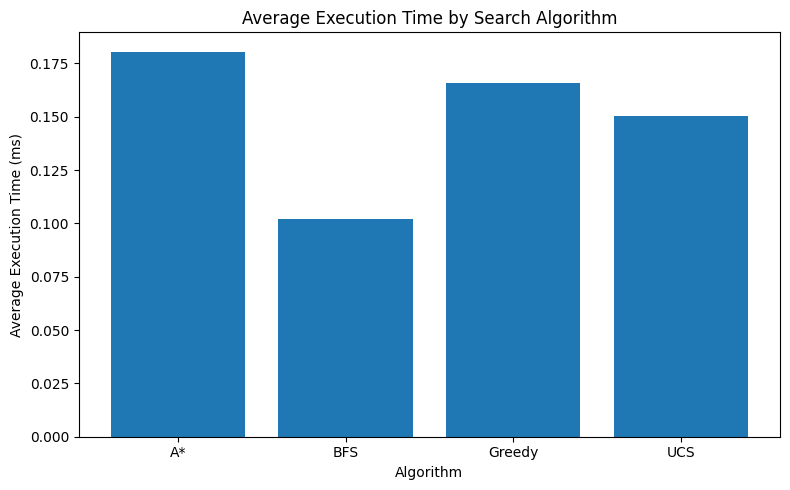

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Time_ms"]
)

plt.title("Average Execution Time by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Execution Time (ms)")

plt.tight_layout()
plt.show()

Step 16 — Average Path Distance graph

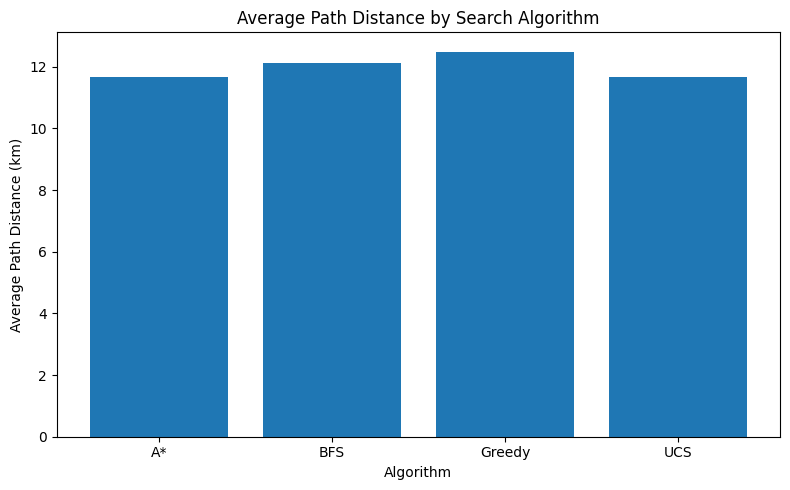

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Distance_km"]
)

plt.title("Average Path Distance by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Path Distance (km)")

plt.tight_layout()
plt.show()

Step 17 — Average Number of Stops

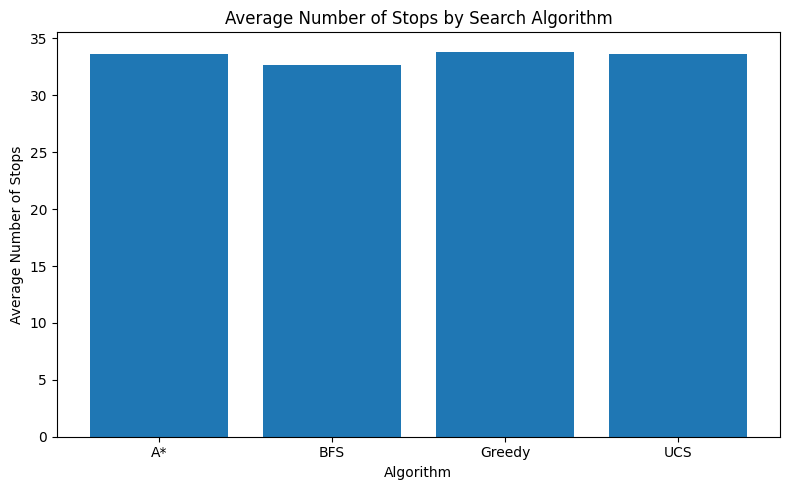

In [44]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Stops"]
)

plt.title("Average Number of Stops by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Number of Stops")

plt.tight_layout()
plt.show()

Step 18 — Nodes Expanded by Distance Group

In [45]:
group_summary = results_df.groupby(
    ["Distance_Group", "Algorithm"]
)["Nodes_Expanded"].mean().reset_index()

display(group_summary.round(2))

,Distance_Group,Algorithm,Nodes_Expanded
0,Long,A*,55.2
1,Long,BFS,148.6
2,Long,Greedy,67.2
3,Long,UCS,125.0
4,Medium,A*,105.6
5,Medium,BFS,169.4
6,Medium,Greedy,80.8
7,Medium,UCS,155.4
8,Short,A*,121.8
9,Short,BFS,274.4


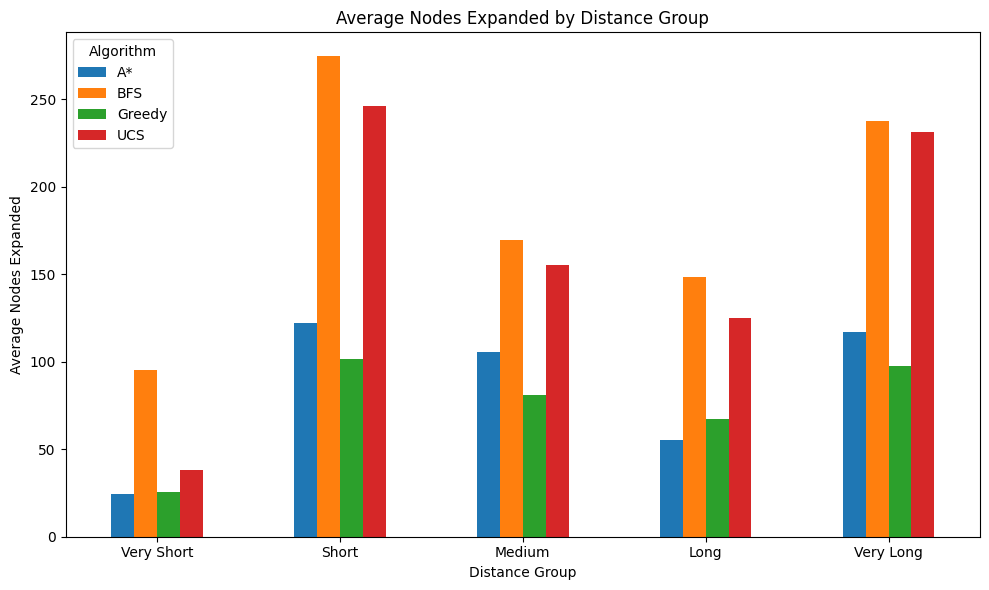

In [46]:
pivot_nodes = group_summary.pivot(
    index="Distance_Group",
    columns="Algorithm",
    values="Nodes_Expanded"
)

pivot_nodes = pivot_nodes.reindex([
    "Very Short",
    "Short",
    "Medium",
    "Long",
    "Very Long"
])

pivot_nodes.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Nodes Expanded by Distance Group")
plt.xlabel("Distance Group")
plt.ylabel("Average Nodes Expanded")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Step 19 — Save your graphs

In [47]:
import os

os.makedirs("figures", exist_ok=True)

print("Figures folder created.")

Figures folder created.


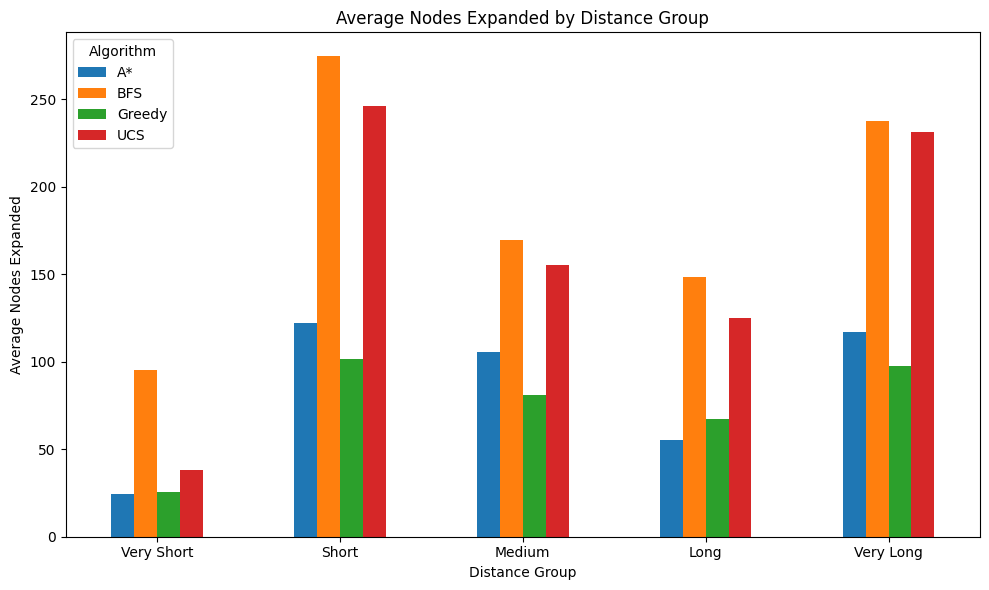

In [48]:
pivot_nodes.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Nodes Expanded by Distance Group")
plt.xlabel("Distance Group")
plt.ylabel("Average Nodes Expanded")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "figures/nodes_by_distance_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 20A — average_nodes_expanded.png
average_execution_time.png
average_path_distance.png
nodes_by_distance_group.png

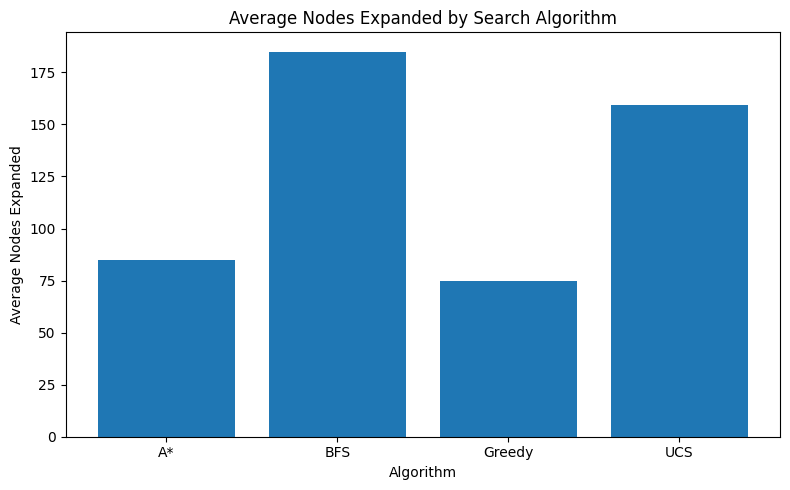

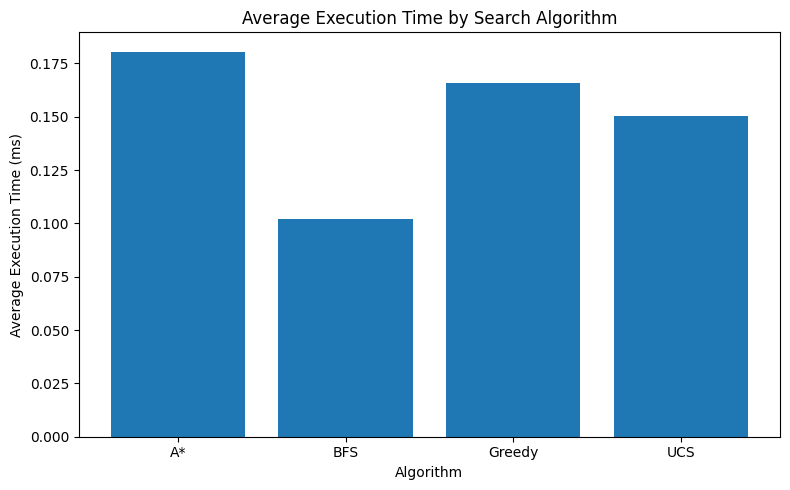

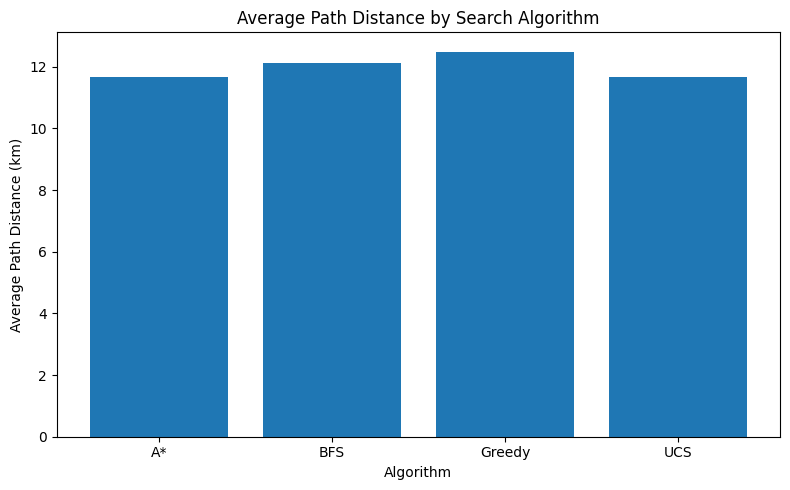

All three graphs saved successfully.


In [49]:


# 1. Average Nodes Expanded
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Nodes_Expanded"]
)

plt.title("Average Nodes Expanded by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Nodes Expanded")

plt.tight_layout()

plt.savefig(
    "figures/average_nodes_expanded.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Average Execution Time
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Time_ms"]
)

plt.title("Average Execution Time by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Execution Time (ms)")

plt.tight_layout()

plt.savefig(
    "figures/average_execution_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Average Path Distance
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Algorithm"],
    summary["Average_Distance_km"]
)

plt.title("Average Path Distance by Search Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Average Path Distance (km)")

plt.tight_layout()

plt.savefig(
    "figures/average_path_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("All three graphs saved successfully.")

In [50]:


# Compare route distances for the same 25 pairs
distance_table = results_df.pivot(
    index="Pair_ID",
    columns="Algorithm",
    values="Distance_km"
)

# Find the minimum distance for each pair
minimum_distance = distance_table.min(axis=1)

# Count how often each algorithm matched the minimum
comparison = pd.DataFrame({
    "Algorithm": distance_table.columns,
    "Pairs_Matching_Minimum": [
        np.isclose(
            distance_table[algorithm],
            minimum_distance,
            atol=1e-8,
            rtol=0
        ).sum()
        for algorithm in distance_table.columns
    ]
})

comparison["Total_Pairs"] = len(distance_table)

display(comparison)

# Show Pair 6 as a detailed example
display(
    results_df.loc[
        results_df["Pair_ID"] == 6,
        ["Algorithm", "Stops", "Distance_km",
         "Nodes_Expanded", "Time_ms"]
    ].round(4)
)

,Algorithm,Pairs_Matching_Minimum,Total_Pairs
0,A*,25,25
1,BFS,24,25
2,Greedy,16,25
3,UCS,25,25


,Algorithm,Stops,Distance_km,Nodes_Expanded,Time_ms
20,BFS,29,25.3718,231,0.1106
21,UCS,53,13.6455,217,0.1987
22,Greedy,46,25.2108,107,0.2201
23,A*,53,13.6455,93,0.1993


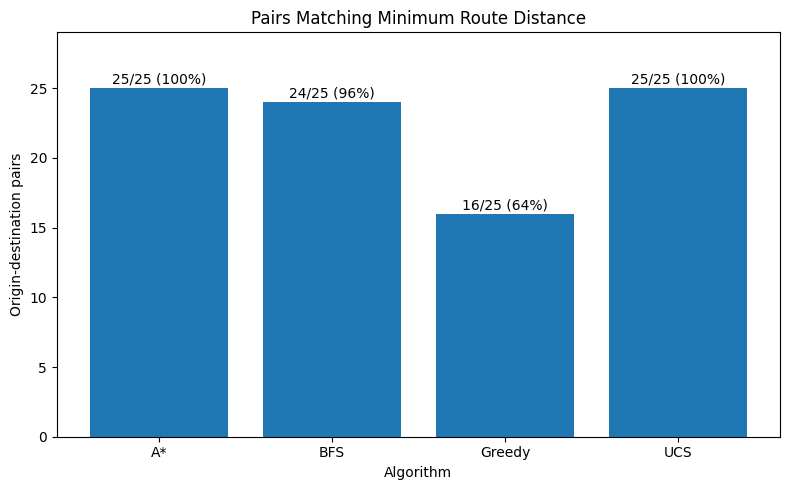

In [51]:


# Figure 4: match-counts using the same absolute tolerance as the report
plt.figure(figsize=(8, 5))
plt.bar(comparison["Algorithm"], comparison["Pairs_Matching_Minimum"])
for x, v in enumerate(comparison["Pairs_Matching_Minimum"]):
    plt.text(x, v+0.3, f"{v}/25 ({v/25:.0%})", ha="center", fontsize=10)
plt.ylim(0, 29)
plt.title("Pairs Matching Minimum Route Distance")
plt.xlabel("Algorithm")
plt.ylabel("Origin-destination pairs")
plt.tight_layout()
plt.savefig("figures/minimum_route_agreement.png", dpi=300, bbox_inches="tight")
plt.show()
